# IntelliSense Backtest Analysis
Compare the performance of **Fixed Q-table**, **Q-learning**, and **DQN** strategies across different tickers.

---

In [6]:
import pandas as pd
import matplotlib.pyplot as plt
import mplfinance as mpf
import json
import os
import numpy as np
from IPython.display import display, Markdown, HTML

def compute_metrics(trades_df, stock_df):
    """Compute Max DD, Alpha (vs S&P 500), Sharpe Ratio, and Win Rate."""
    
    portfolio_values = trades_df['portfolio_value'].values
    
    # --- Max Drawdown ---
    running_max = np.maximum.accumulate(portfolio_values)
    drawdowns = (running_max - portfolio_values) / running_max
    max_dd = np.max(drawdowns) * 100
    
    # --- Total Return ---
    initial_val = portfolio_values[0]
    final_val = portfolio_values[-1]
    total_return = (final_val - initial_val) / initial_val
    
    # --- Alpha (vs S&P 500 benchmark) ---
    dates = pd.to_datetime(trades_df['date'])
    n_years = (dates.iloc[-1] - dates.iloc[0]).days / 365.25
    sp500_annual_return = 0.10
    sp500_period_return = (1 + sp500_annual_return) ** n_years - 1
    alpha = (total_return - sp500_period_return) * 100
    
    # --- Sharpe Ratio (annualized, weekly data, 0% risk-free) ---
    weekly_returns = np.diff(portfolio_values) / portfolio_values[:-1]
    if np.std(weekly_returns) > 0:
        sharpe = (np.mean(weekly_returns) / np.std(weekly_returns)) * np.sqrt(52)
    else:
        sharpe = 0.0
    
    # --- Win Rate (only count trades where shares > 0) ---
    real_buys = trades_df[(trades_df['action'] == 'BUY') & (trades_df['shares'] > 0)]
    real_sells = trades_df[(trades_df['action'] == 'SELL') & (trades_df['shares'] > 0)]
    
    wins = 0
    total_trades = 0
    buy_prices = []
    avg_entry = None
    prev_action = None
    
    for _, row in trades_df.iterrows():
        if row['action'] == 'BUY' and row['shares'] > 0:
            if prev_action != 'BUY':
                buy_prices = []
            buy_prices.append(row['price'])
            avg_entry = np.mean(buy_prices)
            prev_action = 'BUY'
        elif row['action'] == 'SELL' and row['shares'] > 0 and avg_entry is not None:
            if row['price'] > avg_entry:
                wins += 1
            total_trades += 1
            prev_action = 'SELL'
    
    win_rate = (wins / total_trades * 100) if total_trades > 0 else 0.0
    
    return {
        'max_dd': max_dd,
        'alpha': alpha,
        'sharpe': sharpe,
        'win_rate': win_rate,
        'total_return': total_return * 100,
        'final_val': final_val,
        'n_buys': len(real_buys),
        'n_sells': len(real_sells),
        'total_trades': total_trades,
        'wins': wins
    }


def build_trade_log(trades_df):
    """Build a styled trade log table showing only executed BUY/SELL (shares > 0)."""
    # Filter to only executed trades (shares > 0)
    active = trades_df[
        (trades_df['action'].isin(['BUY', 'SELL'])) & (trades_df['shares'] > 0)
    ].copy()
    active = active.reset_index(drop=True)
    
    # Format columns
    log = pd.DataFrame()
    log['Date'] = pd.to_datetime(active['date']).dt.strftime('%Y-%m-%d')
    log['Action'] = active['action']
    log['Price'] = active['price'].map('${:,.2f}'.format)
    log['Shares'] = active['shares'].map('{:,.0f}'.format)
    log['Value'] = active['value'].map('${:,.2f}'.format)
    log['Portfolio'] = active['portfolio_value'].map('${:,.2f}'.format)
    
    return log


def style_trade_log(log):
    """Apply color styling to the trade log."""
    def color_action(val):
        if val == 'BUY':
            return 'color: #00c853; font-weight: bold'
        elif val == 'SELL':
            return 'color: #ff1744; font-weight: bold'
        return ''
    
    styled = log.style.applymap(
        color_action, subset=['Action']
    ).set_properties(**{
        'text-align': 'right',
        'font-size': '12px',
        'padding': '4px 8px',
    }).set_table_styles([
        {'selector': 'th', 'props': [
            ('background-color', '#2d2d44'),
            ('color', 'white'),
            ('font-size', '13px'),
            ('text-align', 'center'),
            ('padding', '6px 10px'),
        ]},
        {'selector': 'td', 'props': [
            ('border-bottom', '1px solid #444'),
        ]},
    ]).hide(axis='index')
    
    return styled


def plot_ticker(ticker, method='DQN_Price_Only'):
    """Plot candlestick chart with buy/sell arrows and trade log."""
    results_dir = 'test_results'
    data_dir = 'data'
    
    # --- Load trade history ---
    history_file = os.path.join(results_dir, f'{ticker}_{method}_history.json')
    if not os.path.exists(history_file):
        print(f'No trade history found for {ticker} ({method}) at {history_file}')
        return
    
    with open(history_file, 'r') as f:
        trades = json.load(f)
    trades_df = pd.DataFrame(trades)
    trades_df['date'] = pd.to_datetime(trades_df['date'])
    
    # --- Load weekly stock data ---
    stock_file = os.path.join(data_dir, f'{ticker}_weekly_stock_data.csv')
    if not os.path.exists(stock_file):
        print(f'No stock data found for {ticker} at {stock_file}')
        return
    
    stock_df = pd.read_csv(stock_file, index_col=0, parse_dates=True)
    stock_df.columns = [c.strip().title() for c in stock_df.columns]
    stock_df = stock_df.sort_index()
    
    # --- Adjust OHLC prices for stock splits/dividends ---
    if 'Adjusted_Close' in stock_df.columns and 'Close' in stock_df.columns:
        adj_factor = stock_df['Adjusted_Close'] / stock_df['Close']
        adj_factor = adj_factor.replace([np.inf, -np.inf], np.nan).fillna(1.0)
        for col in ['Open', 'High', 'Low', 'Close']:
            stock_df[col] = stock_df[col] * adj_factor
    
    # Filter stock data to backtest period
    start_date = trades_df['date'].min()
    end_date = trades_df['date'].max()
    stock_df = stock_df[(stock_df.index >= start_date) & (stock_df.index <= end_date + pd.Timedelta(days=7))]
    
    if stock_df.empty:
        print(f'No stock data in the backtest date range for {ticker}')
        return
    
    # --- Compute performance metrics ---
    metrics = compute_metrics(trades_df, stock_df)
    
    # --- Extract only EXECUTED BUY and SELL trades (shares > 0) ---
    buys = trades_df[(trades_df['action'] == 'BUY') & (trades_df['shares'] > 0)].copy()
    sells = trades_df[(trades_df['action'] == 'SELL') & (trades_df['shares'] > 0)].copy()
    
    buy_markers = pd.Series(np.nan, index=stock_df.index, dtype=float)
    sell_markers = pd.Series(np.nan, index=stock_df.index, dtype=float)
    
    for _, trade in buys.iterrows():
        trade_date = trade['date']
        nearest_idx = stock_df.index.get_indexer([trade_date], method='nearest')[0]
        if nearest_idx >= 0 and nearest_idx < len(stock_df):
            nearest_date = stock_df.index[nearest_idx]
            buy_markers[nearest_date] = stock_df.loc[nearest_date, 'Low'] * 0.97
    
    for _, trade in sells.iterrows():
        trade_date = trade['date']
        nearest_idx = stock_df.index.get_indexer([trade_date], method='nearest')[0]
        if nearest_idx >= 0 and nearest_idx < len(stock_df):
            nearest_date = stock_df.index[nearest_idx]
            sell_markers[nearest_date] = stock_df.loc[nearest_date, 'High'] * 1.03
    
    # --- Build mplfinance addplots ---
    addplots = []
    if buy_markers.notna().any():
        addplots.append(mpf.make_addplot(
            buy_markers, type='scatter', marker='^', markersize=100,
            color='#00c853', secondary_y=False
        ))
    if sell_markers.notna().any():
        addplots.append(mpf.make_addplot(
            sell_markers, type='scatter', marker='v', markersize=100,
            color='#ff1744', secondary_y=False
        ))
    
    # --- Custom style ---
    custom_style = mpf.make_mpf_style(
        base_mpf_style='nightclouds',
        marketcolors=mpf.make_marketcolors(
            up='#00c853', down='#ff1744',
            edge={'up': '#00c853', 'down': '#ff1744'},
            wick={'up': '#00c853', 'down': '#ff1744'},
            volume='in'
        ),
        facecolor='#1a1a2e',
        edgecolor='#1a1a2e',
        figcolor='#1a1a2e',
        gridcolor='#2d2d44',
        gridstyle='--',
        gridaxis='both',
        y_on_right=True,
        rc={'font.size': 10}
    )
    
    # --- Title with core stats ---
    title = (f'{ticker} — {method.replace("_", " ")} Strategy\n'
             f'Return: {metrics["total_return"]:+.1f}%  |  '
             f'Final: ${metrics["final_val"]:,.0f}  |  '
             f'Buys: {metrics["n_buys"]}  |  Sells: {metrics["n_sells"]}')
    
    # --- Plot ---
    fig, axes = mpf.plot(
        stock_df, type='candle', style=custom_style,
        volume=True, addplot=addplots if addplots else None,
        title=title, figsize=(18, 10),
        tight_layout=False, returnfig=True,
        panel_ratios=(4, 1),
        warn_too_much_data=9999
    )
    
    # Add legend
    ax_main = axes[0]
    ax_main.scatter([], [], marker='^', s=100, color='#00c853', label='BUY')
    ax_main.scatter([], [], marker='v', s=100, color='#ff1744', label='SELL')
    ax_main.legend(loc='upper left', fontsize=12, framealpha=0.7,
                  facecolor='#1a1a2e', edgecolor='#444',
                  labelcolor='white')
    
    # --- Metrics box below the chart ---
    metrics_text = (
        f'Max DD: {metrics["max_dd"]:.1f}%    '
        f'Alpha (vs S&P): {metrics["alpha"]:+.1f}%    '
        f'Sharpe: {metrics["sharpe"]:.2f}    '
        f'Win Rate: {metrics["win_rate"]:.0f}% '
        f'({metrics["wins"]}/{metrics["total_trades"]} trades)'
    )
    
    fig.text(
        0.5, 0.01, metrics_text,
        ha='center', va='bottom', fontsize=13,
        color='white', fontweight='bold',
        fontstyle='italic',
        bbox=dict(boxstyle='round,pad=0.5', facecolor='#2d2d44',
                  edgecolor='#555', alpha=0.9)
    )
    
    fig.subplots_adjust(bottom=0.08)
    plt.show()
    
    # --- Trade Log Table ---
    display(Markdown(f'### {ticker} — Trade Log ({method.replace("_", " ")})'))
    log = build_trade_log(trades_df)
    display(style_trade_log(log))


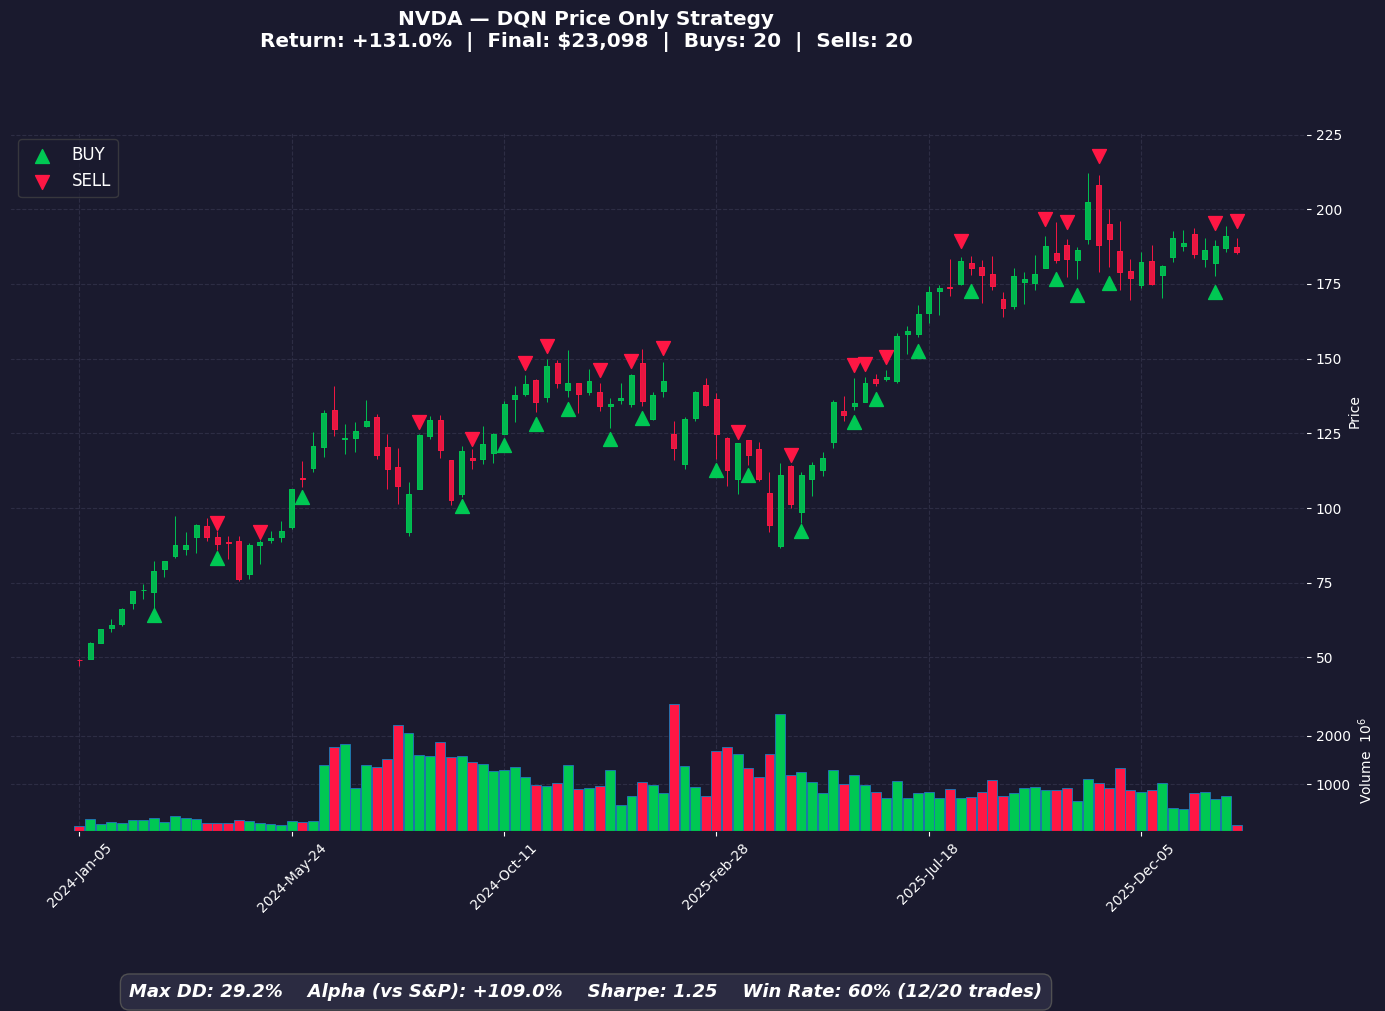

### NVDA — Trade Log (DQN Price Only)

/var/folders/pz/_0kh2t797553_kjgmmh7_0fc0000gn/T/ipykernel_92233/3521736162.py:106: FutureWarning: Styler.applymap has been deprecated. Use Styler.map instead.
  styled = log.style.applymap(


Date,Action,Price,Shares,Value,Portfolio
2024-02-20,BUY,$69.41,143,"$9,926.18","$9,990.07"
2024-04-01,SELL,$90.32,143,"$12,915.41","$12,966.39"
2024-04-08,BUY,$87.09,148,"$12,889.20","$12,953.50"
2024-05-06,SELL,$92.09,148,"$13,629.86","$13,680.53"
2024-06-03,BUY,$114.94,118,"$13,563.18","$13,666.97"
2024-08-19,SELL,$129.95,118,"$15,333.55","$15,422.02"
2024-09-16,BUY,$116.74,131,"$15,293.04","$15,406.72"
2024-09-23,SELL,$116.22,131,"$15,224.94","$15,323.40"
2024-10-14,BUY,$138.02,110,"$15,182.59","$15,308.22"
2024-10-28,SELL,$140.47,110,"$15,452.00","$15,562.18"


In [7]:
plot_ticker('NVDA', method='DQN_Price_Only')


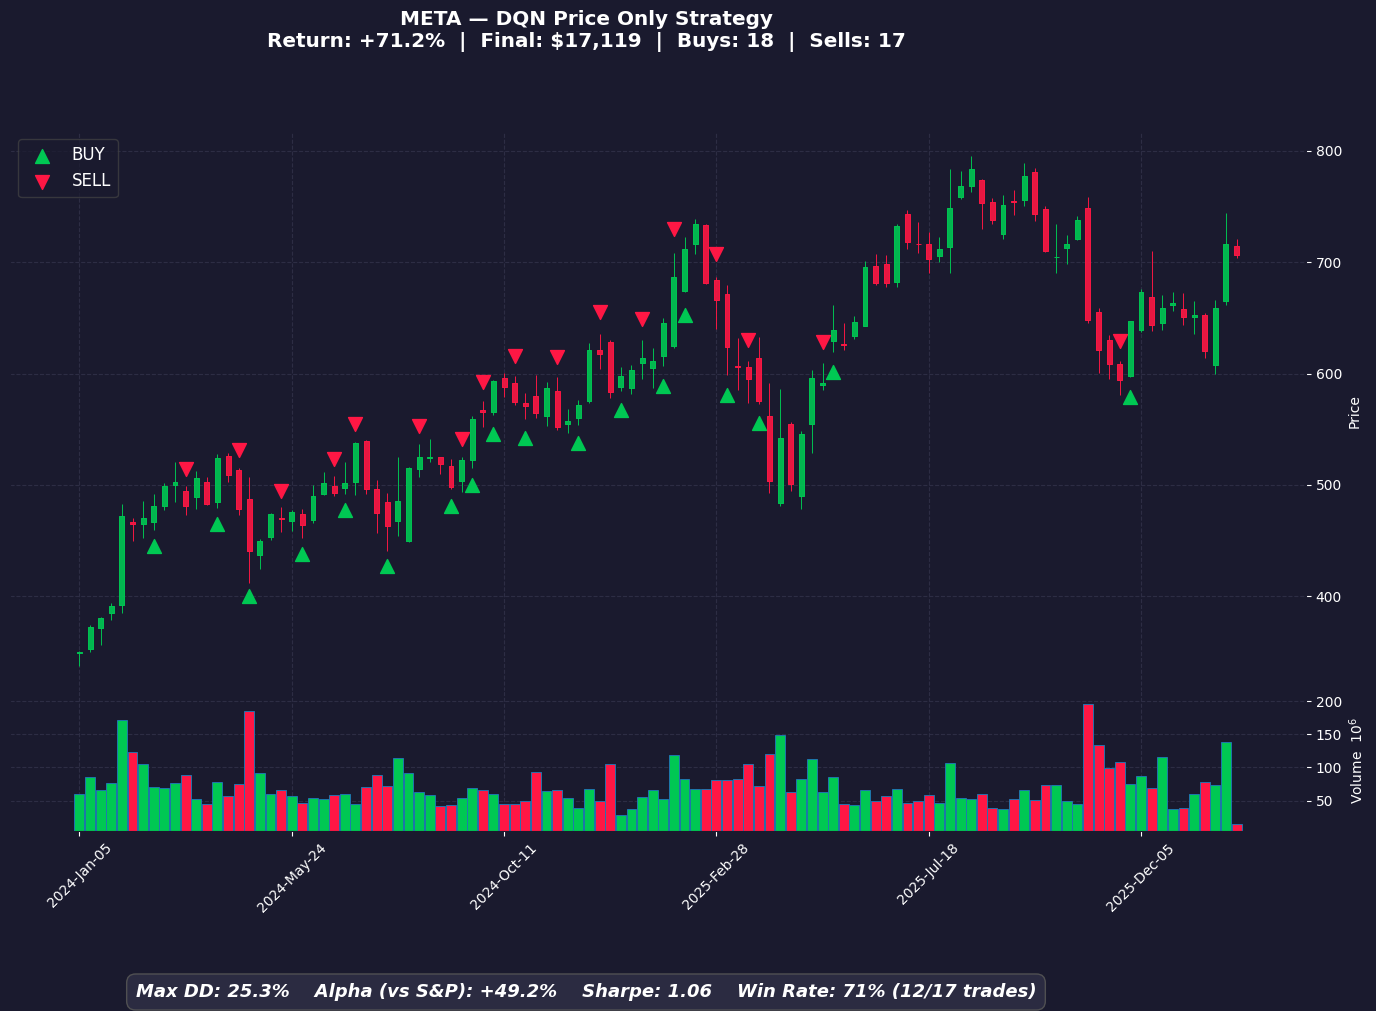

### META — Trade Log (DQN Price Only)

/var/folders/pz/_0kh2t797553_kjgmmh7_0fc0000gn/T/ipykernel_92233/3521736162.py:106: FutureWarning: Styler.applymap has been deprecated. Use Styler.map instead.
  styled = log.style.applymap(


Date,Action,Price,Shares,Value,Portfolio
2024-02-20,BUY,$468.50,21,"$9,838.59","$9,990.16"
2024-03-18,SELL,$494.09,21,"$10,375.84","$10,517.04"
2024-04-08,BUY,$516.23,20,"$10,324.56","$10,506.72"
2024-04-22,SELL,$478.93,20,"$9,578.53","$9,751.11"
2024-04-29,BUY,$430.10,22,"$9,462.25","$9,741.64"
2024-05-20,SELL,$466.11,22,"$10,254.45","$10,523.59"
2024-06-03,BUY,$474.71,22,"$10,443.65","$10,513.15"
2024-06-24,SELL,$496.50,22,"$10,922.97","$10,981.55"
2024-07-01,BUY,$502.24,21,"$10,547.05","$10,971.00"
2024-07-08,SELL,$526.76,21,"$11,061.99","$11,474.88"


In [8]:
plot_ticker('META', method='DQN_Price_Only')


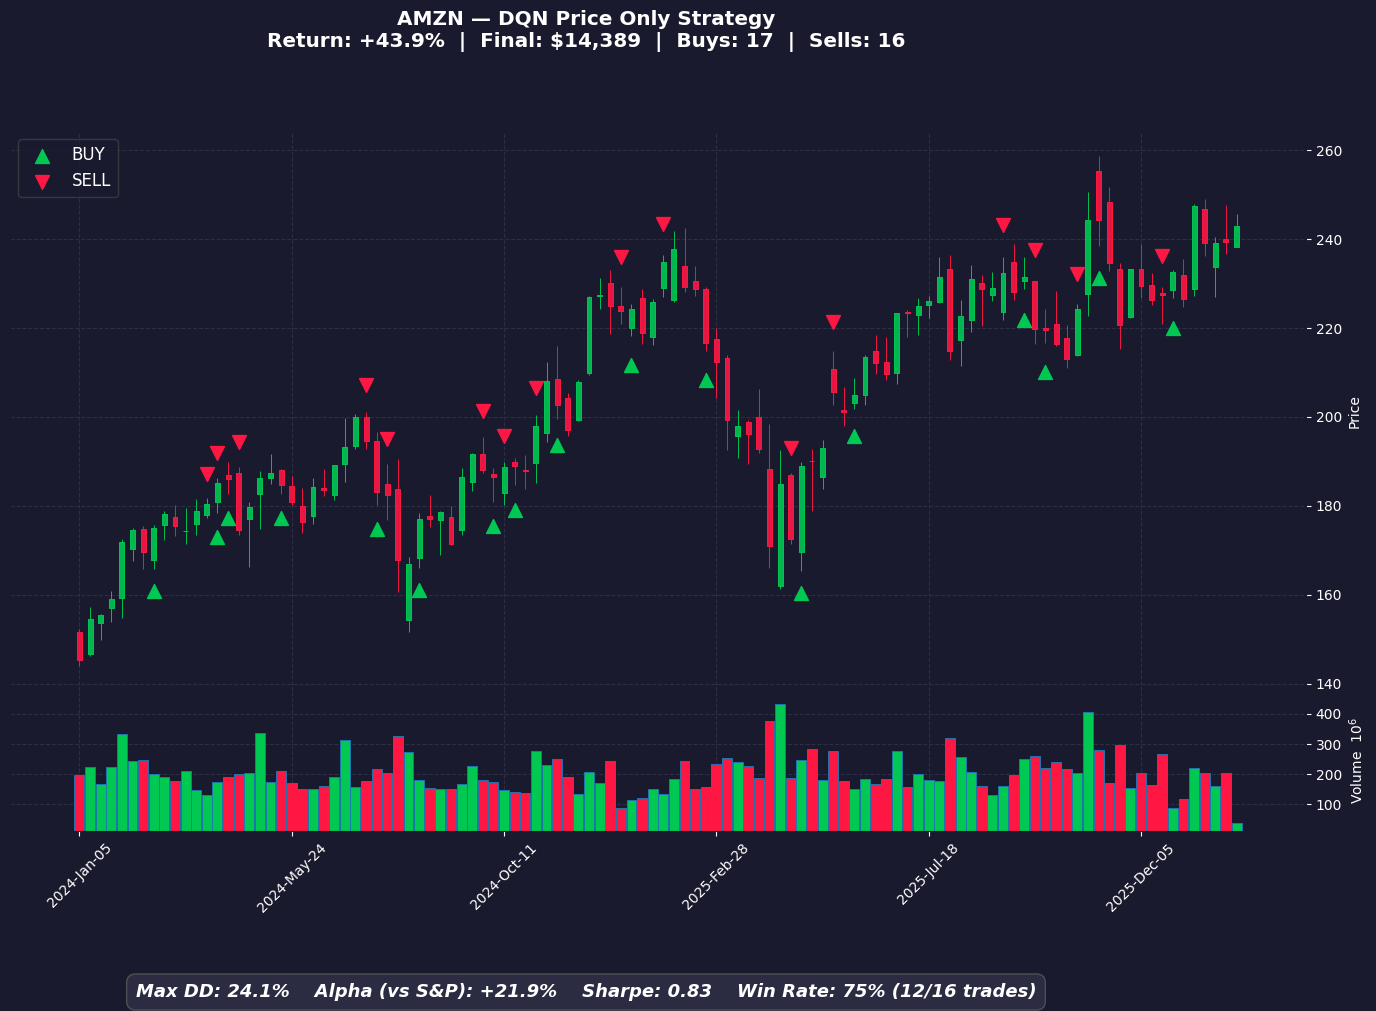

### AMZN — Trade Log (DQN Price Only)

/var/folders/pz/_0kh2t797553_kjgmmh7_0fc0000gn/T/ipykernel_92233/3521736162.py:106: FutureWarning: Styler.applymap has been deprecated. Use Styler.map instead.
  styled = log.style.applymap(


Date,Action,Price,Shares,Value,Portfolio
2024-02-20,BUY,$167.08,59,"$9,857.72","$9,990.14"
2024-03-25,SELL,$179.71,59,"$10,602.89","$10,724.71"
2024-04-01,BUY,$180.97,59,"$10,677.23","$10,714.03"
2024-04-08,SELL,$185.19,59,"$10,926.21","$10,952.09"
2024-04-15,BUY,$183.62,59,"$10,833.58","$10,941.25"
2024-04-22,SELL,$177.23,59,"$10,456.57","$10,553.79"
2024-05-20,BUY,$183.54,57,"$10,461.78","$10,543.32"
2024-07-15,SELL,$192.72,57,"$10,985.04","$11,055.60"
2024-07-22,BUY,$182.55,60,"$10,953.00","$11,044.65"
2024-07-29,SELL,$183.20,60,"$10,992.00","$11,072.65"


In [9]:
plot_ticker('AMZN', method='DQN_Price_Only')


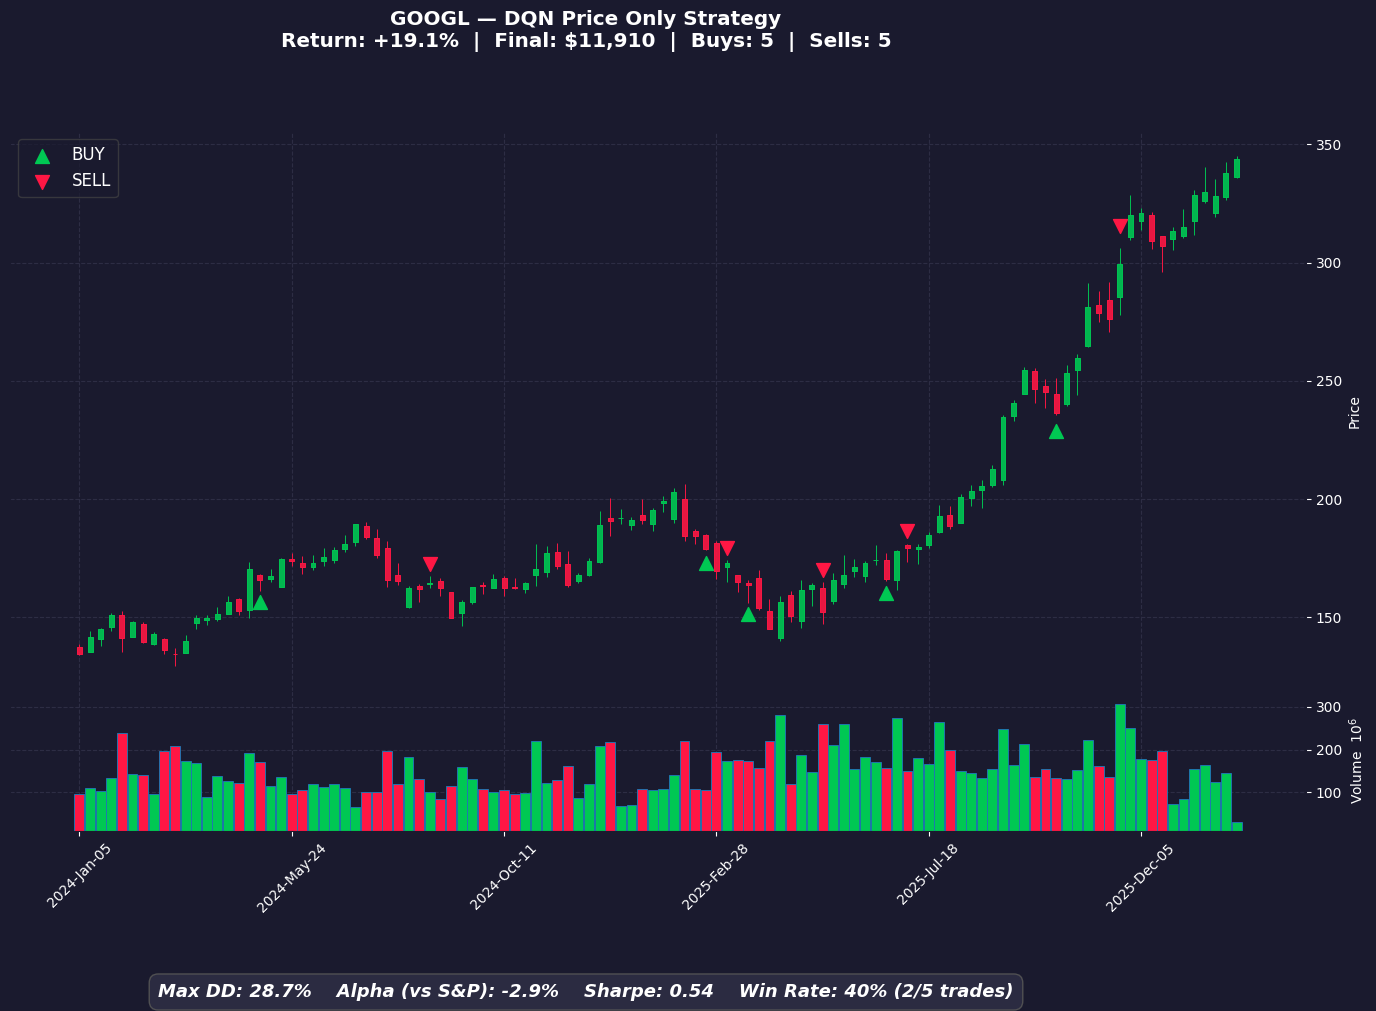

### GOOGL — Trade Log (DQN Price Only)

/var/folders/pz/_0kh2t797553_kjgmmh7_0fc0000gn/T/ipykernel_92233/3521736162.py:106: FutureWarning: Styler.applymap has been deprecated. Use Styler.map instead.
  styled = log.style.applymap(


Date,Action,Price,Shares,Value,Portfolio
2024-05-06,BUY,$166.83,59,"$9,842.92","$9,990.16"
2024-08-26,SELL,$165.09,59,"$9,740.44","$9,877.94"
2025-02-24,BUY,$178.54,55,"$9,819.76","$9,868.12"
2025-03-10,SELL,$165.41,55,"$9,097.72","$9,136.99"
2025-03-24,BUY,$167.22,54,"$9,029.78","$9,127.96"
2025-05-12,SELL,$158.02,54,"$8,533.27","$8,622.92"
2025-06-23,BUY,$164.93,52,"$8,576.44","$8,614.34"
2025-06-30,SELL,$175.95,52,"$9,149.62","$9,178.37"
2025-10-13,BUY,$243.99,37,"$9,027.51","$9,169.35"
2025-11-24,SELL,$318.37,37,"$11,779.57","$11,909.63"


In [10]:
plot_ticker('GOOGL', method='DQN_Price_Only')


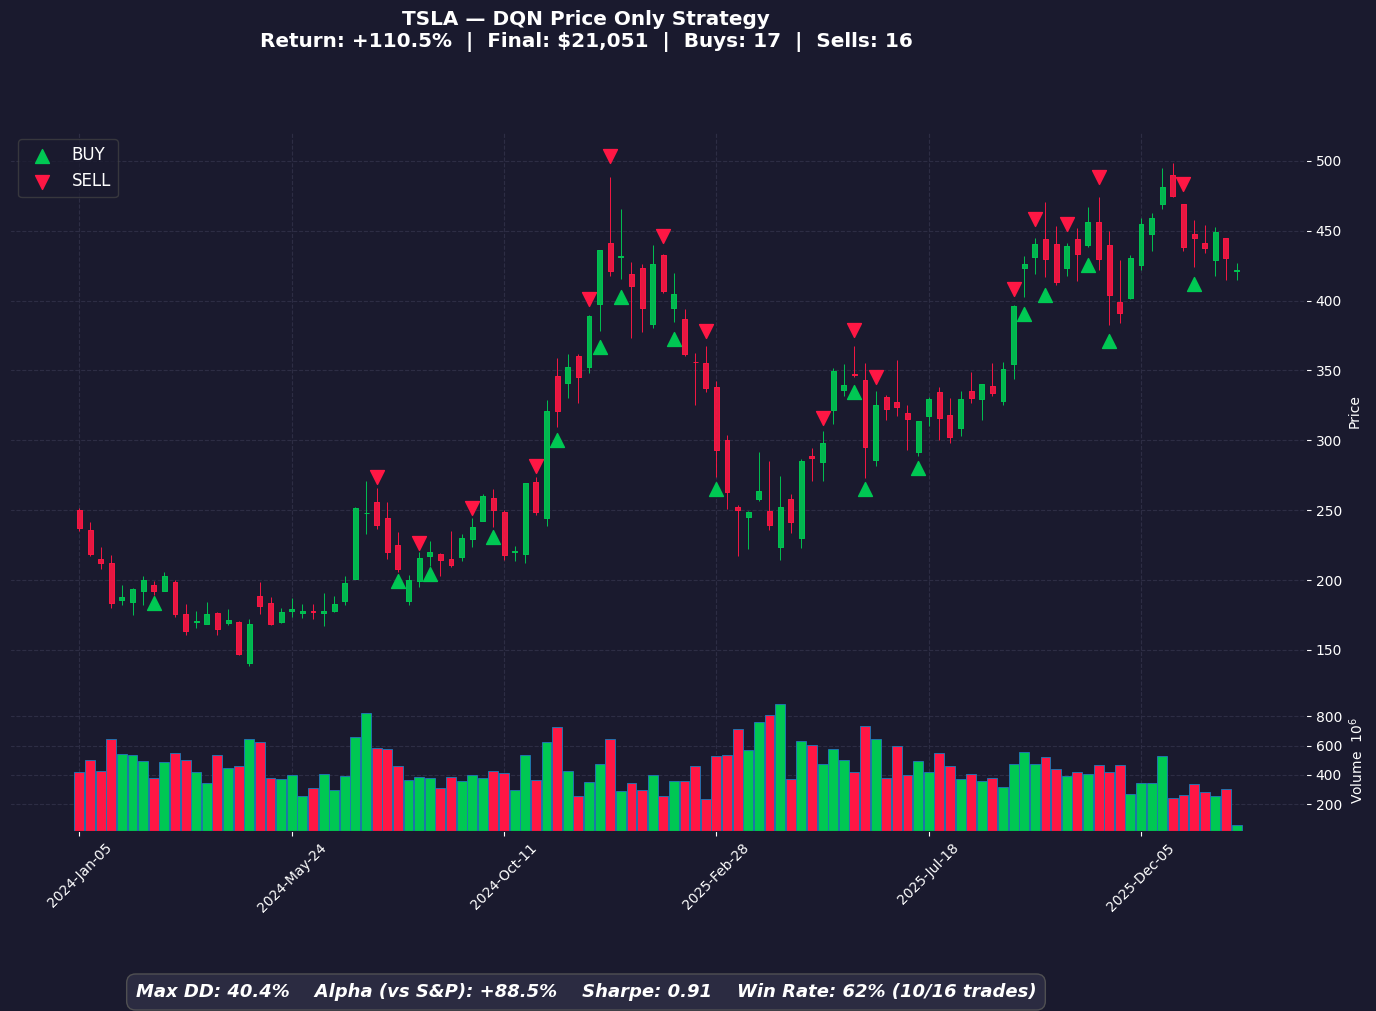

### TSLA — Trade Log (DQN Price Only)

/var/folders/pz/_0kh2t797553_kjgmmh7_0fc0000gn/T/ipykernel_92233/3521736162.py:106: FutureWarning: Styler.applymap has been deprecated. Use Styler.map instead.
  styled = log.style.applymap(


Date,Action,Price,Shares,Value,Portfolio
2024-02-20,BUY,$193.76,51,"$9,881.76","$9,990.12"
2024-07-22,SELL,$251.51,51,"$12,827.01","$12,922.54"
2024-08-05,BUY,$198.88,64,"$12,728.32","$12,909.81"
2024-08-19,SELL,$222.72,64,"$14,254.08","$14,421.32"
2024-08-26,BUY,$213.21,67,"$14,285.07","$14,407.03"
2024-09-23,SELL,$250.00,67,"$16,750.00","$16,855.21"
2024-10-07,BUY,$240.83,69,"$16,617.27","$16,838.60"
2024-11-04,SELL,$242.84,69,"$16,755.96","$16,960.53"
2024-11-18,BUY,$338.74,50,"$16,937.00","$16,943.59"
2024-12-09,SELL,$389.79,50,"$19,489.50","$19,476.60"


In [11]:
plot_ticker('TSLA', method='DQN_Price_Only')

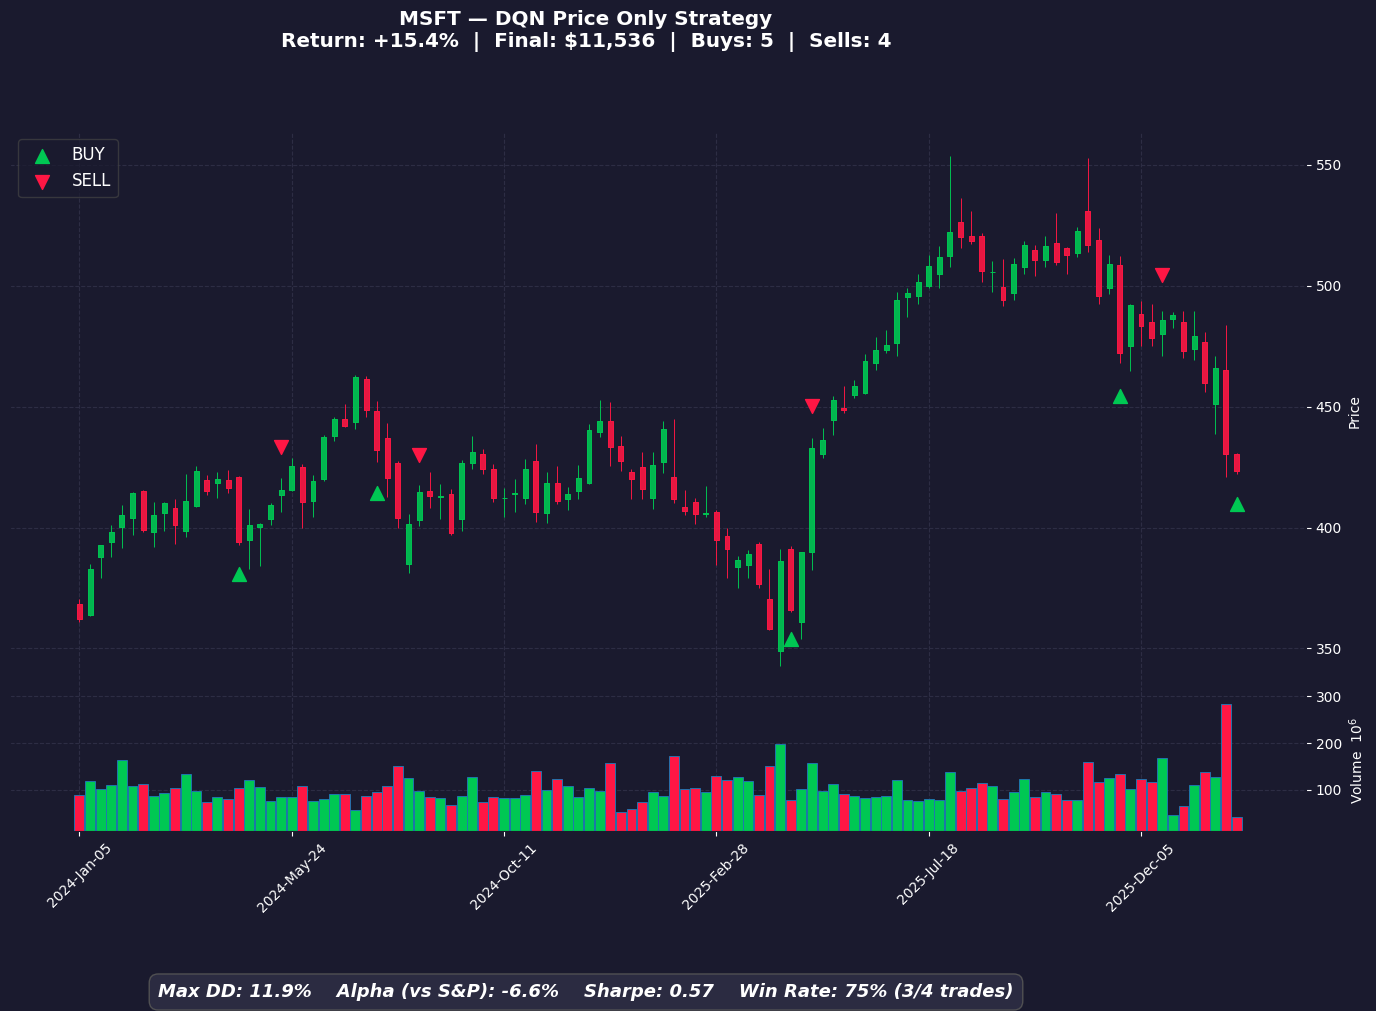

### MSFT — Trade Log (DQN Price Only)

/var/folders/pz/_0kh2t797553_kjgmmh7_0fc0000gn/T/ipykernel_92233/3521736162.py:106: FutureWarning: Styler.applymap has been deprecated. Use Styler.map instead.
  styled = log.style.applymap(


Date,Action,Price,Shares,Value,Portfolio
2024-04-22,BUY,$395.81,25,"$9,895.26","$9,990.10"
2024-05-20,SELL,$420.62,25,"$10,515.54","$10,599.87"
2024-07-22,BUY,$438.03,24,"$10,512.63","$10,589.36"
2024-08-19,SELL,$417.60,24,"$10,022.31","$10,089.02"
2025-04-14,BUY,$385.73,26,"$10,029.01","$10,078.99"
2025-05-05,SELL,$433.83,26,"$11,279.63","$11,318.33"
2025-11-24,BUY,$474.00,23,"$10,902.00","$11,307.43"
2025-12-22,SELL,$484.92,23,"$11,153.16","$11,547.43"
2026-02-02,BUY,$423.37,27,"$11,430.99","$11,536.00"


In [12]:
plot_ticker('MSFT', method='DQN_Price_Only')

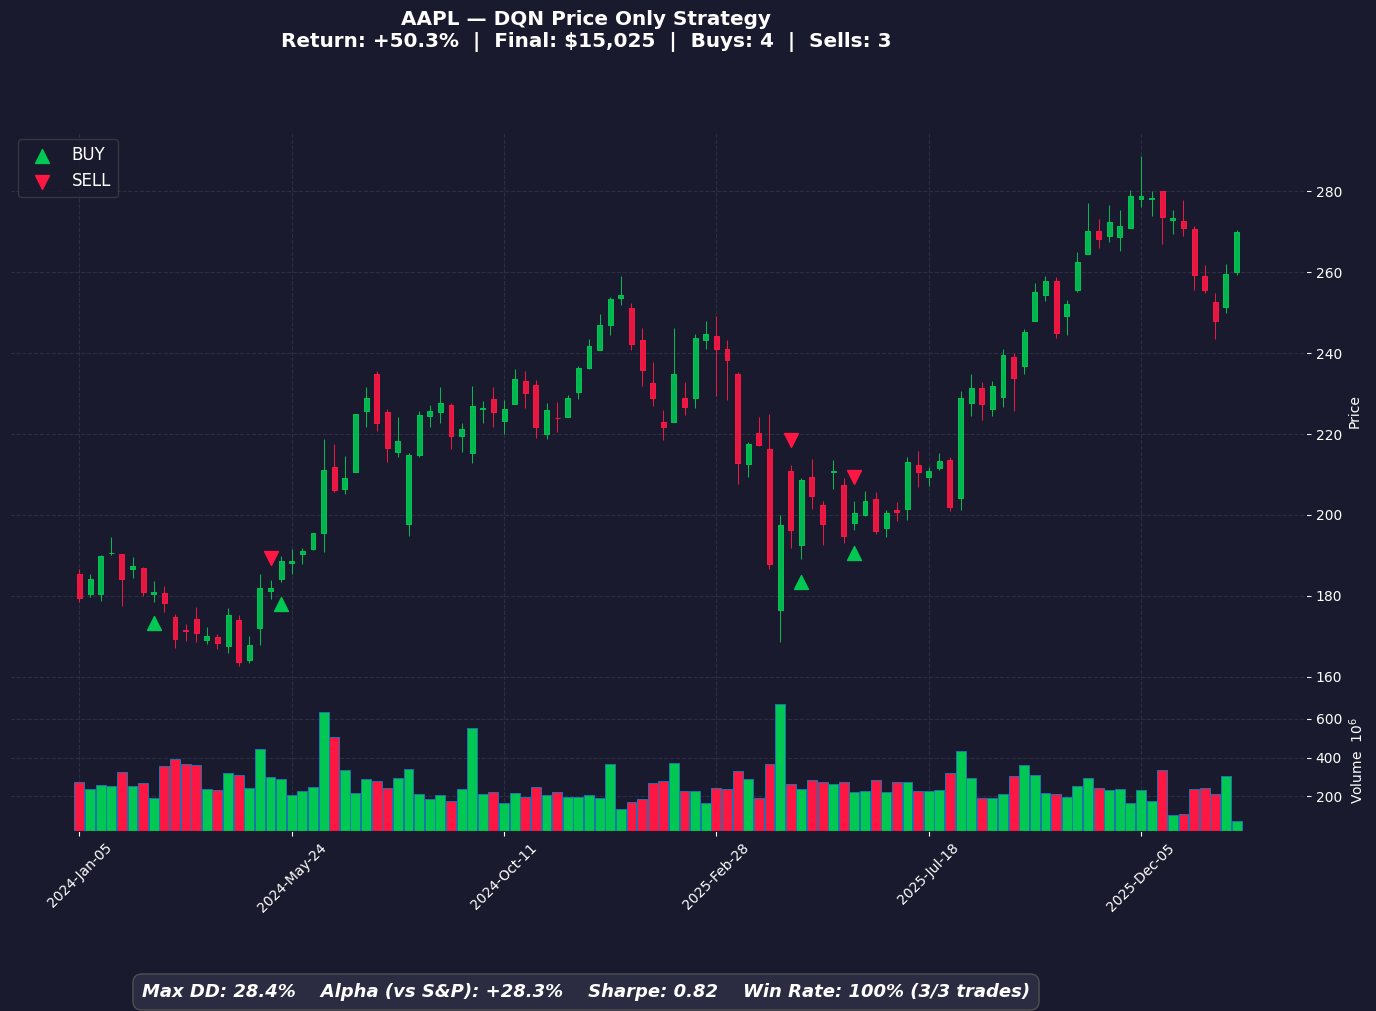

### AAPL — Trade Log (DQN Price Only)

/var/folders/pz/_0kh2t797553_kjgmmh7_0fc0000gn/T/ipykernel_92233/3521736162.py:106: FutureWarning: Styler.applymap has been deprecated. Use Styler.map instead.
  styled = log.style.applymap(


Date,Action,Price,Shares,Value,Portfolio
2024-02-20,BUY,$180.10,55,"$9,905.71","$9,990.09"
2024-05-13,SELL,$185.04,55,"$10,177.11","$10,251.32"
2024-05-20,BUY,$189.77,53,"$10,057.63","$10,241.26"
2025-04-14,SELL,$201.84,53,"$10,697.76","$10,870.69"
2025-04-21,BUY,$192.52,56,"$10,780.88","$10,859.91"
2025-05-27,SELL,$199.79,56,"$11,188.15","$11,255.99"
2025-06-02,BUY,$201.28,55,"$11,070.14","$11,244.92"


In [13]:
plot_ticker('AAPL', method='DQN_Price_Only')

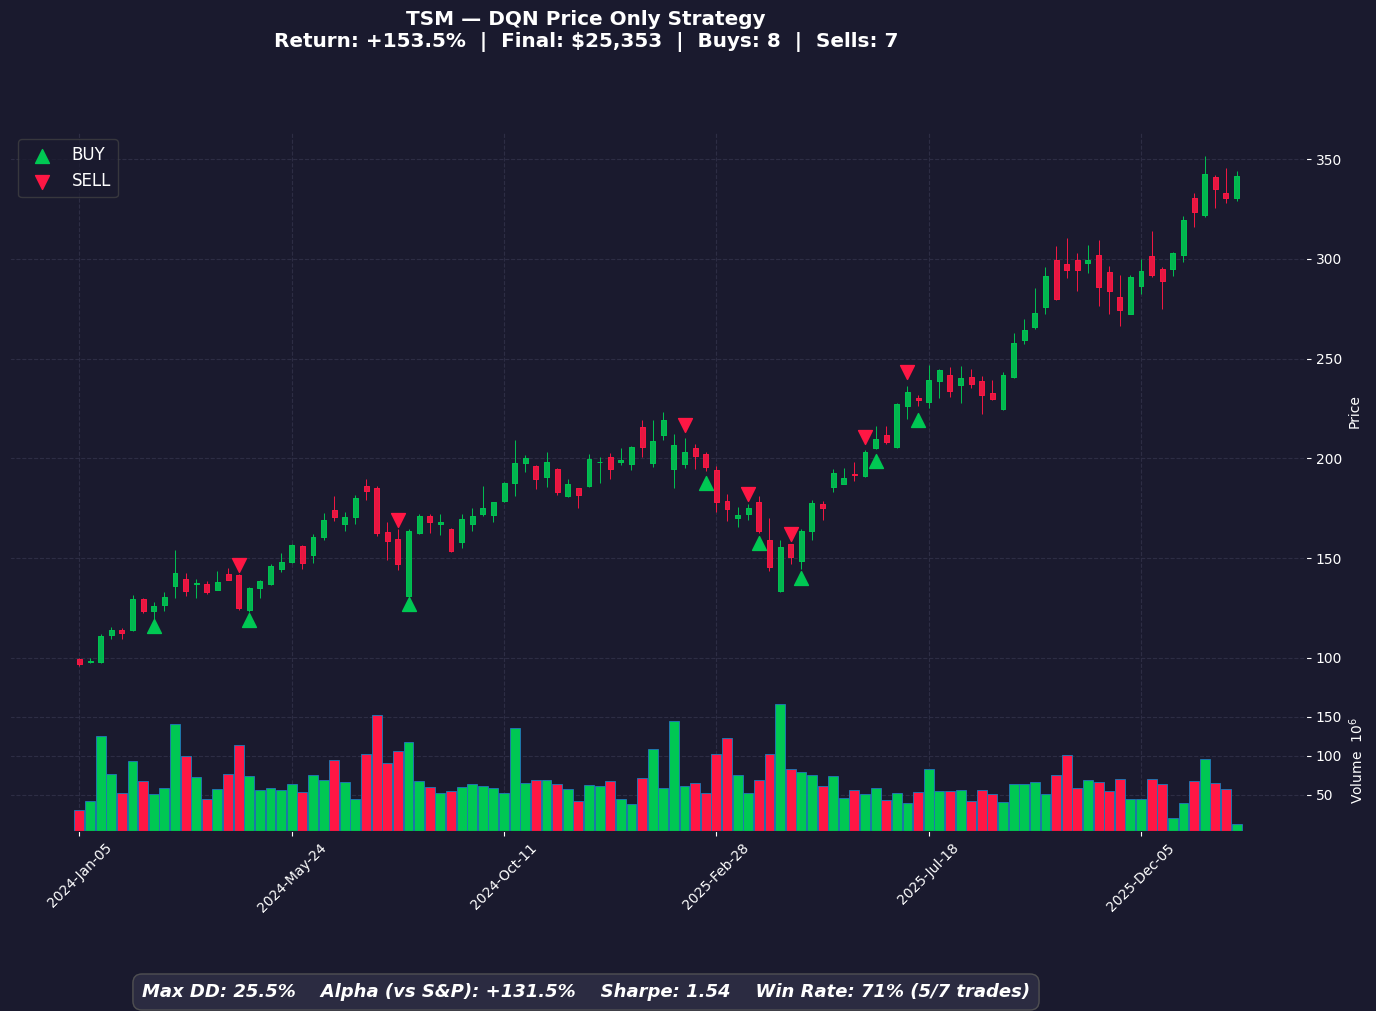

### TSM — Trade Log (DQN Price Only)

/var/folders/pz/_0kh2t797553_kjgmmh7_0fc0000gn/T/ipykernel_92233/3521736162.py:106: FutureWarning: Styler.applymap has been deprecated. Use Styler.map instead.
  styled = log.style.applymap(


Date,Action,Price,Shares,Value,Portfolio
2024-02-20,BUY,$121.97,81,"$9,879.45","$9,990.12"
2024-04-22,SELL,$126.78,81,"$10,269.30","$10,369.70"
2024-04-29,BUY,$135.33,76,"$10,285.18","$10,359.42"
2024-08-05,SELL,$145.02,76,"$11,021.54","$11,084.75"
2024-08-12,BUY,$164.31,67,"$11,008.80","$11,073.74"
2025-02-10,SELL,$205.23,67,"$13,750.69","$13,801.88"
2025-02-18,BUY,$200.09,68,"$13,606.27","$13,788.27"
2025-03-24,SELL,$179.50,68,"$12,206.01","$12,375.81"
2025-03-31,BUY,$164.48,75,"$12,335.93","$12,363.47"
2025-04-14,SELL,$154.41,75,"$11,580.91","$11,596.87"


In [14]:
plot_ticker('TSM', method='DQN_Price_Only')

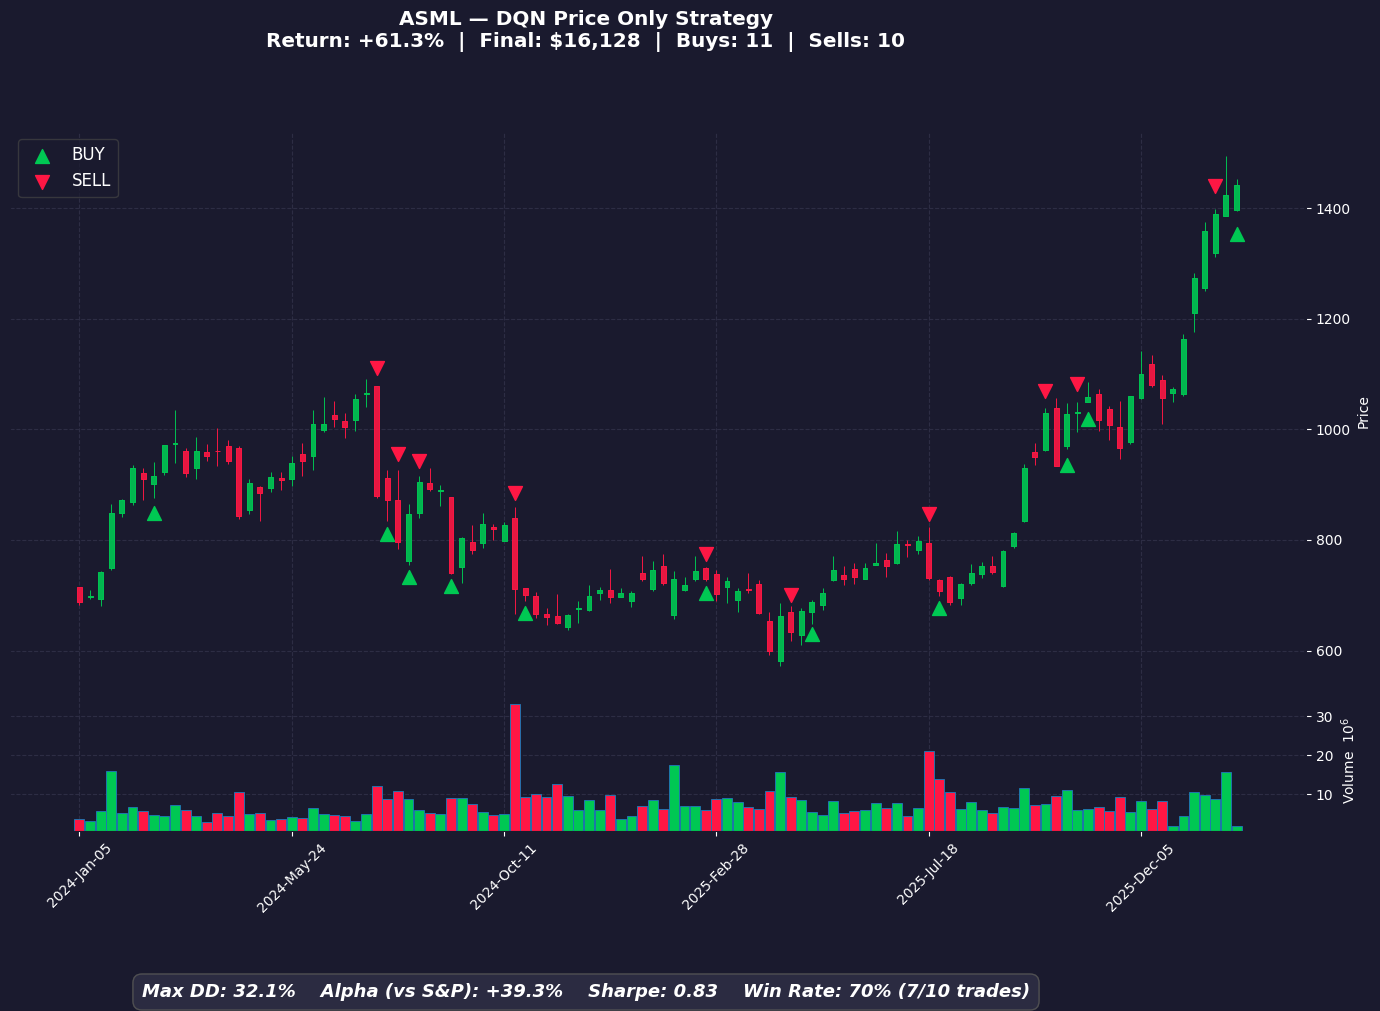

### ASML — Trade Log (DQN Price Only)

/var/folders/pz/_0kh2t797553_kjgmmh7_0fc0000gn/T/ipykernel_92233/3521736162.py:106: FutureWarning: Styler.applymap has been deprecated. Use Styler.map instead.
  styled = log.style.applymap(


Date,Action,Price,Shares,Value,Portfolio
2024-02-20,BUY,$891.62,11,"$9,807.79","$9,990.19"
2024-07-22,SELL,$924.56,11,"$10,170.18","$10,342.42"
2024-07-29,BUY,$856.72,12,"$10,280.65","$10,332.14"
2024-08-05,SELL,$807.32,12,"$9,687.82","$9,729.62"
2024-08-12,BUY,$839.31,11,"$9,232.43","$9,720.39"
2024-08-19,SELL,$918.33,11,"$10,101.59","$10,579.45"
2024-09-03,BUY,$831.96,12,"$9,983.52","$10,569.46"
2024-10-21,SELL,$702.76,12,"$8,433.07","$9,010.58"
2024-10-28,BUY,$697.39,12,"$8,368.71","$9,002.21"
2025-02-18,SELL,$736.94,12,"$8,843.30","$9,467.96"


In [15]:
plot_ticker('ASML', method='DQN_Price_Only')